<a href="https://colab.research.google.com/github/ZiyuCao421/26-CP5046-SIN-CAM-TR3-ICT-Project-1-Analysis-and-Design/blob/main/Assessment2/07_Final_Report/CP5603_Figures_4_5_and_Table_1_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CP5603 Assessment 2 — Figures 4–5 and Table 1

This notebook creates the following final-report artefacts:

- **Figure 4** — Security Control Strategy (prevent, detect, recover).
- **Figure 5** — Strategic Roadmap (12 months, four phases).
- **Table 1** — Evidence Correlation Matrix (evidence against the five primary risks).

The content follows the five-risk register: R01, R03, R04, R05 and R06. It distinguishes evidence from risk treatment; it does not assert a confirmed compromise.

In [1]:
from pathlib import Path
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Patch

# Export directories
FIGURE_DIR = Path('figures')
TABLE_DIR = Path('tables')
FIGURE_DIR.mkdir(exist_ok=True)
TABLE_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
})

# Shared palette: navy = established controls; amber = planned strengthening;
# teal = detection; green = recovery; red = identified concern.
NAVY = '#173F5F'
BLUE = '#247BA0'
TEAL = '#2A9D8F'
AMBER = '#E9A820'
GREEN = '#4E8B57'
RED = '#B71C1C'
GREY = '#6C757D'
LIGHT_GREY = '#F4F6F8'

def add_box(ax, xy, width, height, title, body, edge, face, title_colour=NAVY, body_colour='#1F2933',
            title_size=12, body_size=9):
    """Draw a readable rounded control or roadmap card."""
    x, y = xy
    patch = FancyBboxPatch(
        (x, y), width, height,
        boxstyle='round,pad=0.02,rounding_size=0.04',
        linewidth=1.8, edgecolor=edge, facecolor=face, zorder=2
    )
    ax.add_patch(patch)
    ax.text(x + width/2, y + height - 0.08, title, ha='center', va='top',
            fontsize=title_size, fontweight='bold', color=title_colour, zorder=3)
    ax.text(x + width/2, y + height/2 - 0.05, body, ha='center', va='center',
            fontsize=body_size, color=body_colour, linespacing=1.35, zorder=3)
    return patch


## Figure 4 — Security Control Strategy

The three layers are complementary: preventative controls reduce exposure, detective controls establish visibility and response triggers, and recovery controls restore secure service.

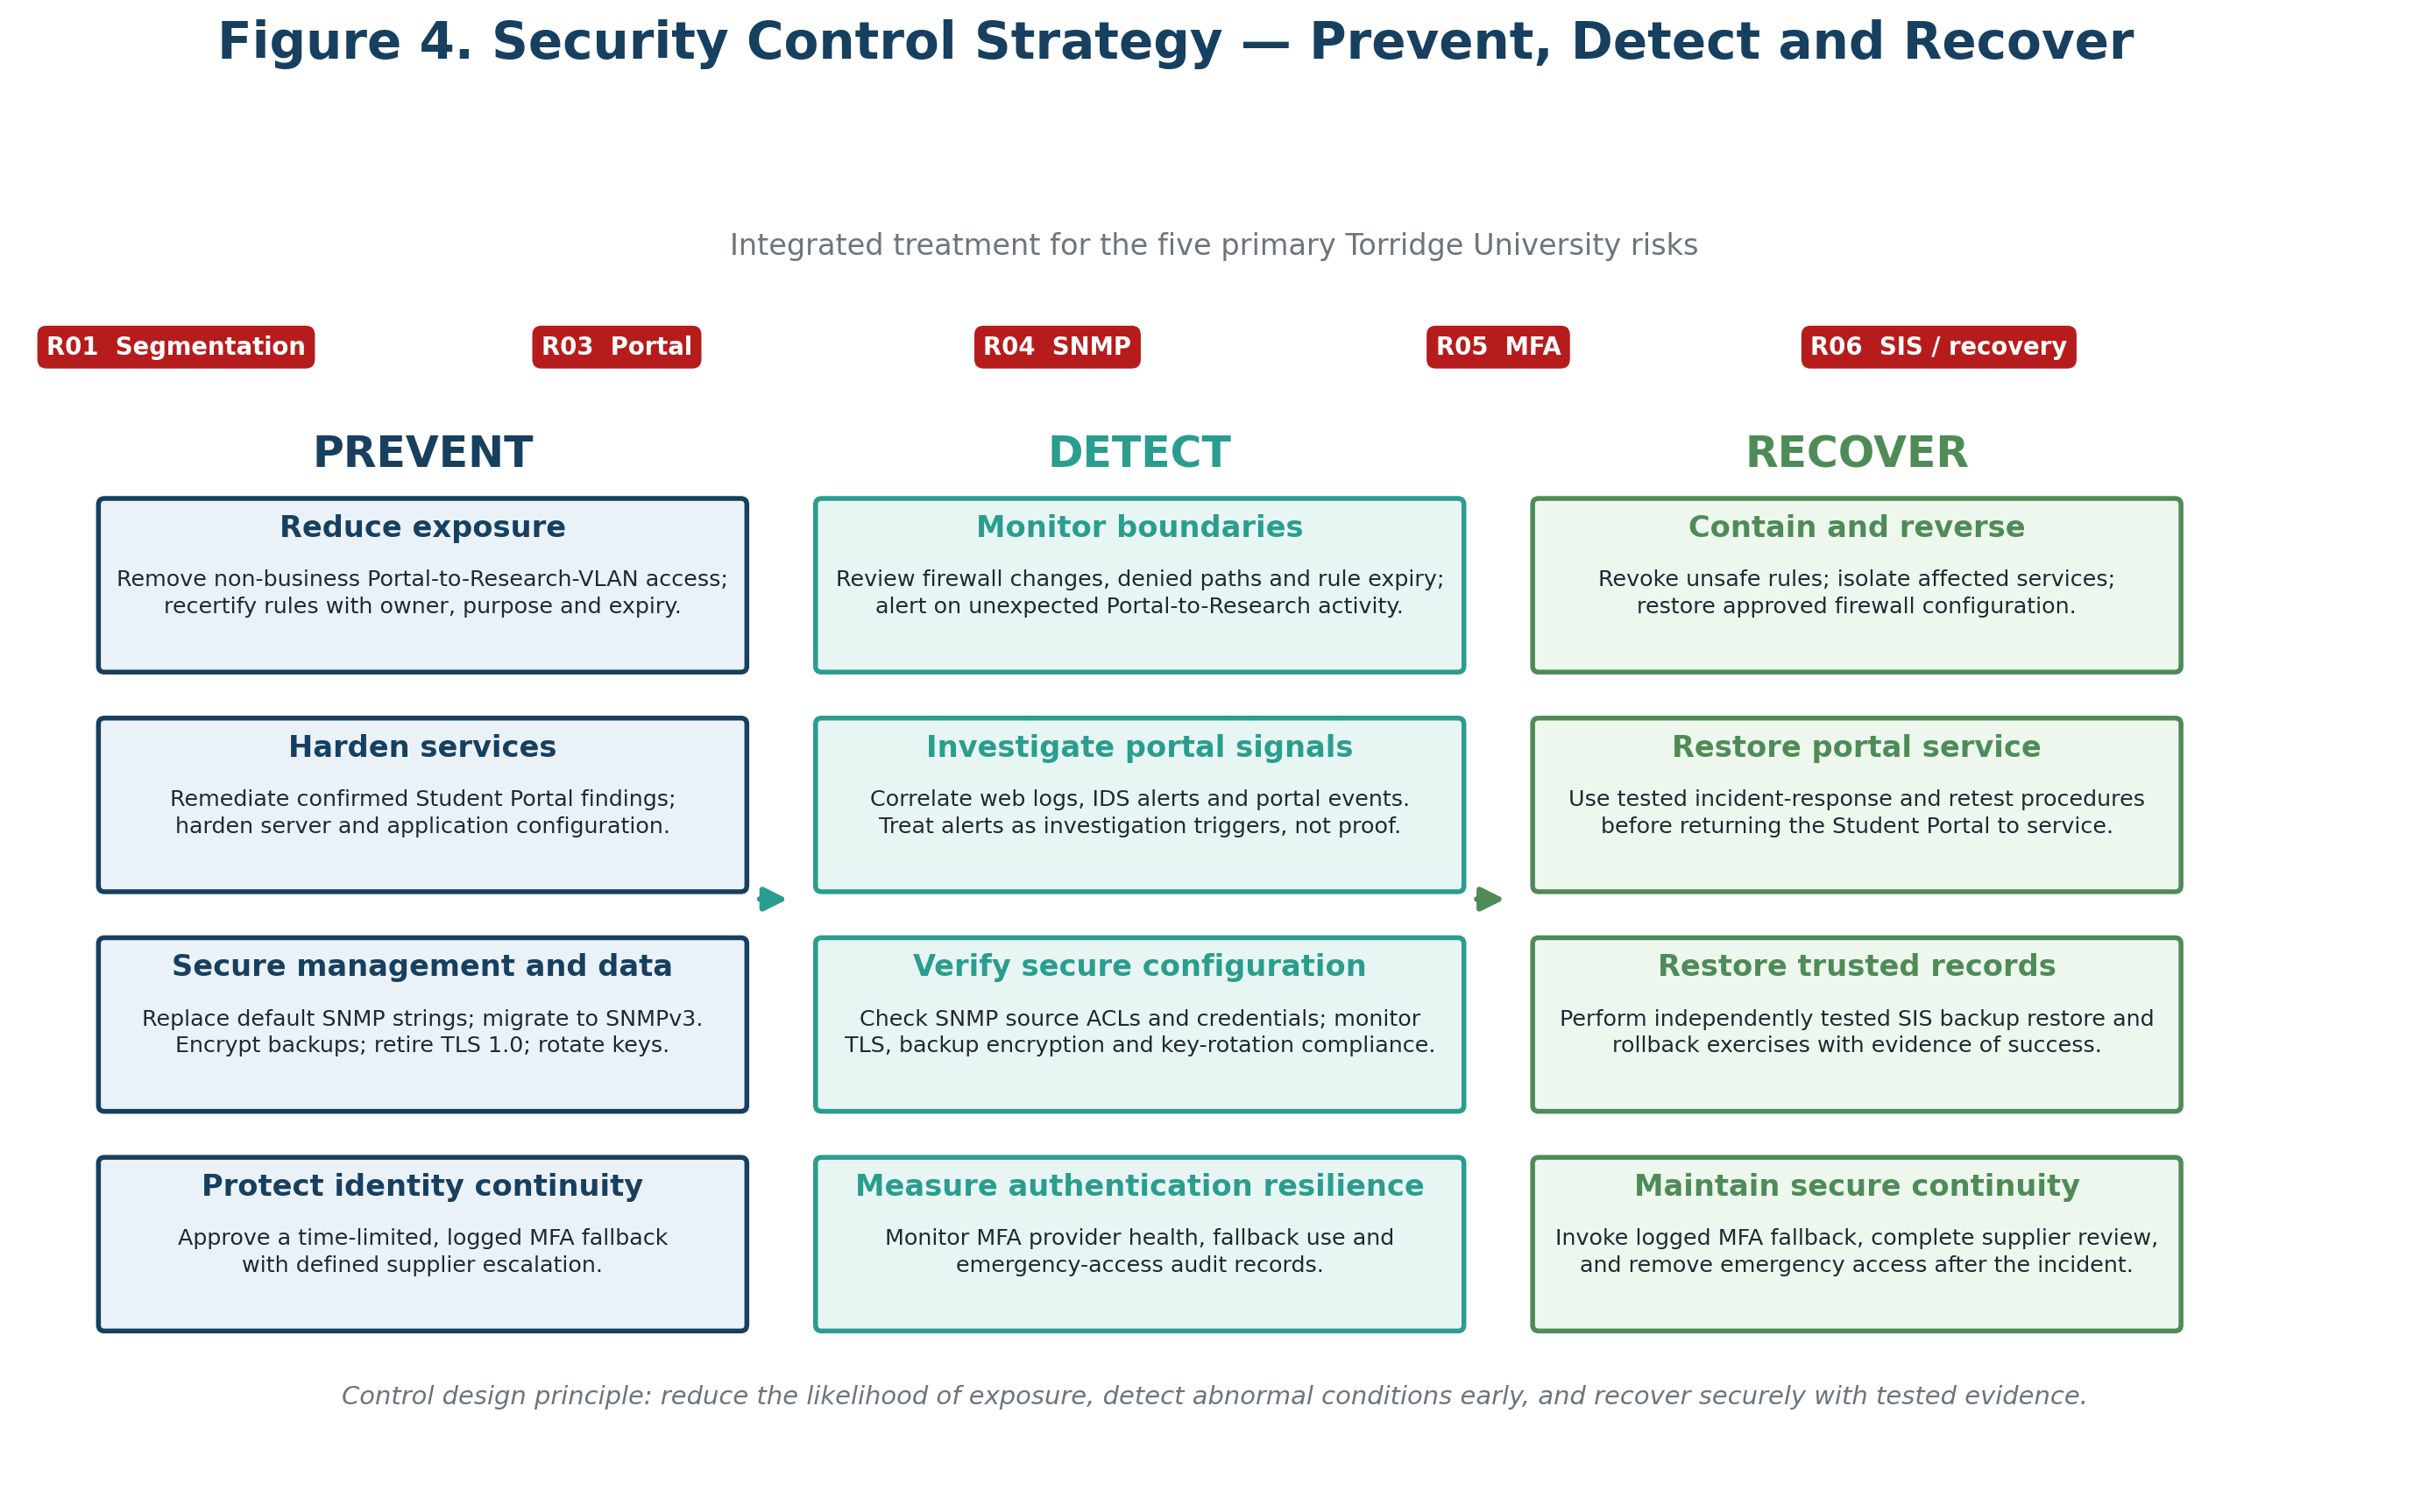

In [2]:
fig, ax = plt.subplots(figsize=(16, 9), dpi=220)
ax.set_xlim(0, 16)
ax.set_ylim(0, 9)
ax.axis('off')

fig.suptitle('Figure 4. Security Control Strategy — Prevent, Detect and Recover',
             fontsize=19, fontweight='bold', color=NAVY, y=0.96)
ax.text(8, 8.35, 'Integrated treatment for the five primary Torridge University risks',
        ha='center', fontsize=11, color=GREY)

# Five risk tags, retained as a traceability aid rather than a risk score.
risk_tags = [
    ('R01', 'Segmentation'), ('R03', 'Portal'), ('R04', 'SNMP'),
    ('R05', 'MFA'), ('R06', 'SIS / recovery')
]
for i, (risk_id, label) in enumerate(risk_tags):
    x = 1.05 + i * 2.95
    ax.text(x, 7.72, f'{risk_id}  {label}', ha='center', va='center', fontsize=9,
            color='white', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.38', facecolor=RED, edgecolor='none'))

columns = [
    (0.55, 'PREVENT', NAVY, '#EAF2F8',
     [('Reduce exposure', 'Remove non-business Portal-to-Research-VLAN access;\nrecertify rules with owner, purpose and expiry.'),
      ('Harden services', 'Remediate confirmed Student Portal findings;\nharden server and application configuration.'),
      ('Secure management and data', 'Replace default SNMP strings; migrate to SNMPv3.\nEncrypt backups; retire TLS 1.0; rotate keys.'),
      ('Protect identity continuity', 'Approve a time-limited, logged MFA fallback\nwith defined supplier escalation.')]),
    (5.35, 'DETECT', TEAL, '#E8F6F3',
     [('Monitor boundaries', 'Review firewall changes, denied paths and rule expiry;\nalert on unexpected Portal-to-Research activity.'),
      ('Investigate portal signals', 'Correlate web logs, IDS alerts and portal events.\nTreat alerts as investigation triggers, not proof.'),
      ('Verify secure configuration', 'Check SNMP source ACLs and credentials; monitor\nTLS, backup encryption and key-rotation compliance.'),
      ('Measure authentication resilience', 'Monitor MFA provider health, fallback use and\nemergency-access audit records.')]),
    (10.15, 'RECOVER', GREEN, '#EDF7ED',
     [('Contain and reverse', 'Revoke unsafe rules; isolate affected services;\nrestore approved firewall configuration.'),
      ('Restore portal service', 'Use tested incident-response and retest procedures\nbefore returning the Student Portal to service.'),
      ('Restore trusted records', 'Perform independently tested SIS backup restore and\nrollback exercises with evidence of success.'),
      ('Maintain secure continuity', 'Invoke logged MFA fallback, complete supplier review,\nand remove emergency access after the incident.')])
]

for x, heading, colour, pale, cards in columns:
    ax.text(x + 2.15, 7.0, heading, ha='center', va='center', fontsize=16,
            fontweight='bold', color=colour)
    for row, (card_title, card_body) in enumerate(cards):
        add_box(ax, (x, 5.55 - row * 1.48), 4.3, 1.13, card_title, card_body,
                edge=colour, face=pale, title_colour=colour, title_size=11, body_size=8.3)

# Arrows state the control-cycle relationship, not a network path.
for start_x, end_x, colour in [(4.92, 5.18, TEAL), (9.72, 9.98, GREEN)]:
    ax.add_patch(FancyArrowPatch((start_x, 4.0), (end_x, 4.0), arrowstyle='-|>',
                                 mutation_scale=18, linewidth=2.1, color=colour))

ax.text(8, 0.6, 'Control design principle: reduce the likelihood of exposure, detect abnormal conditions early, '
                  'and recover securely with tested evidence.',
        ha='center', fontsize=9.5, color=GREY, style='italic')

fig.savefig(FIGURE_DIR / 'Figure_4_Security_Control_Strategy.png', dpi=300, bbox_inches='tight')
fig.savefig(FIGURE_DIR / 'Figure_4_Security_Control_Strategy.svg', bbox_inches='tight')
plt.show()


## Figure 5 — Strategic Roadmap

The roadmap sequences urgent reduction of critical exposure before longer-term resilience and governance work. Dates are relative to approval of the risk-treatment plan.

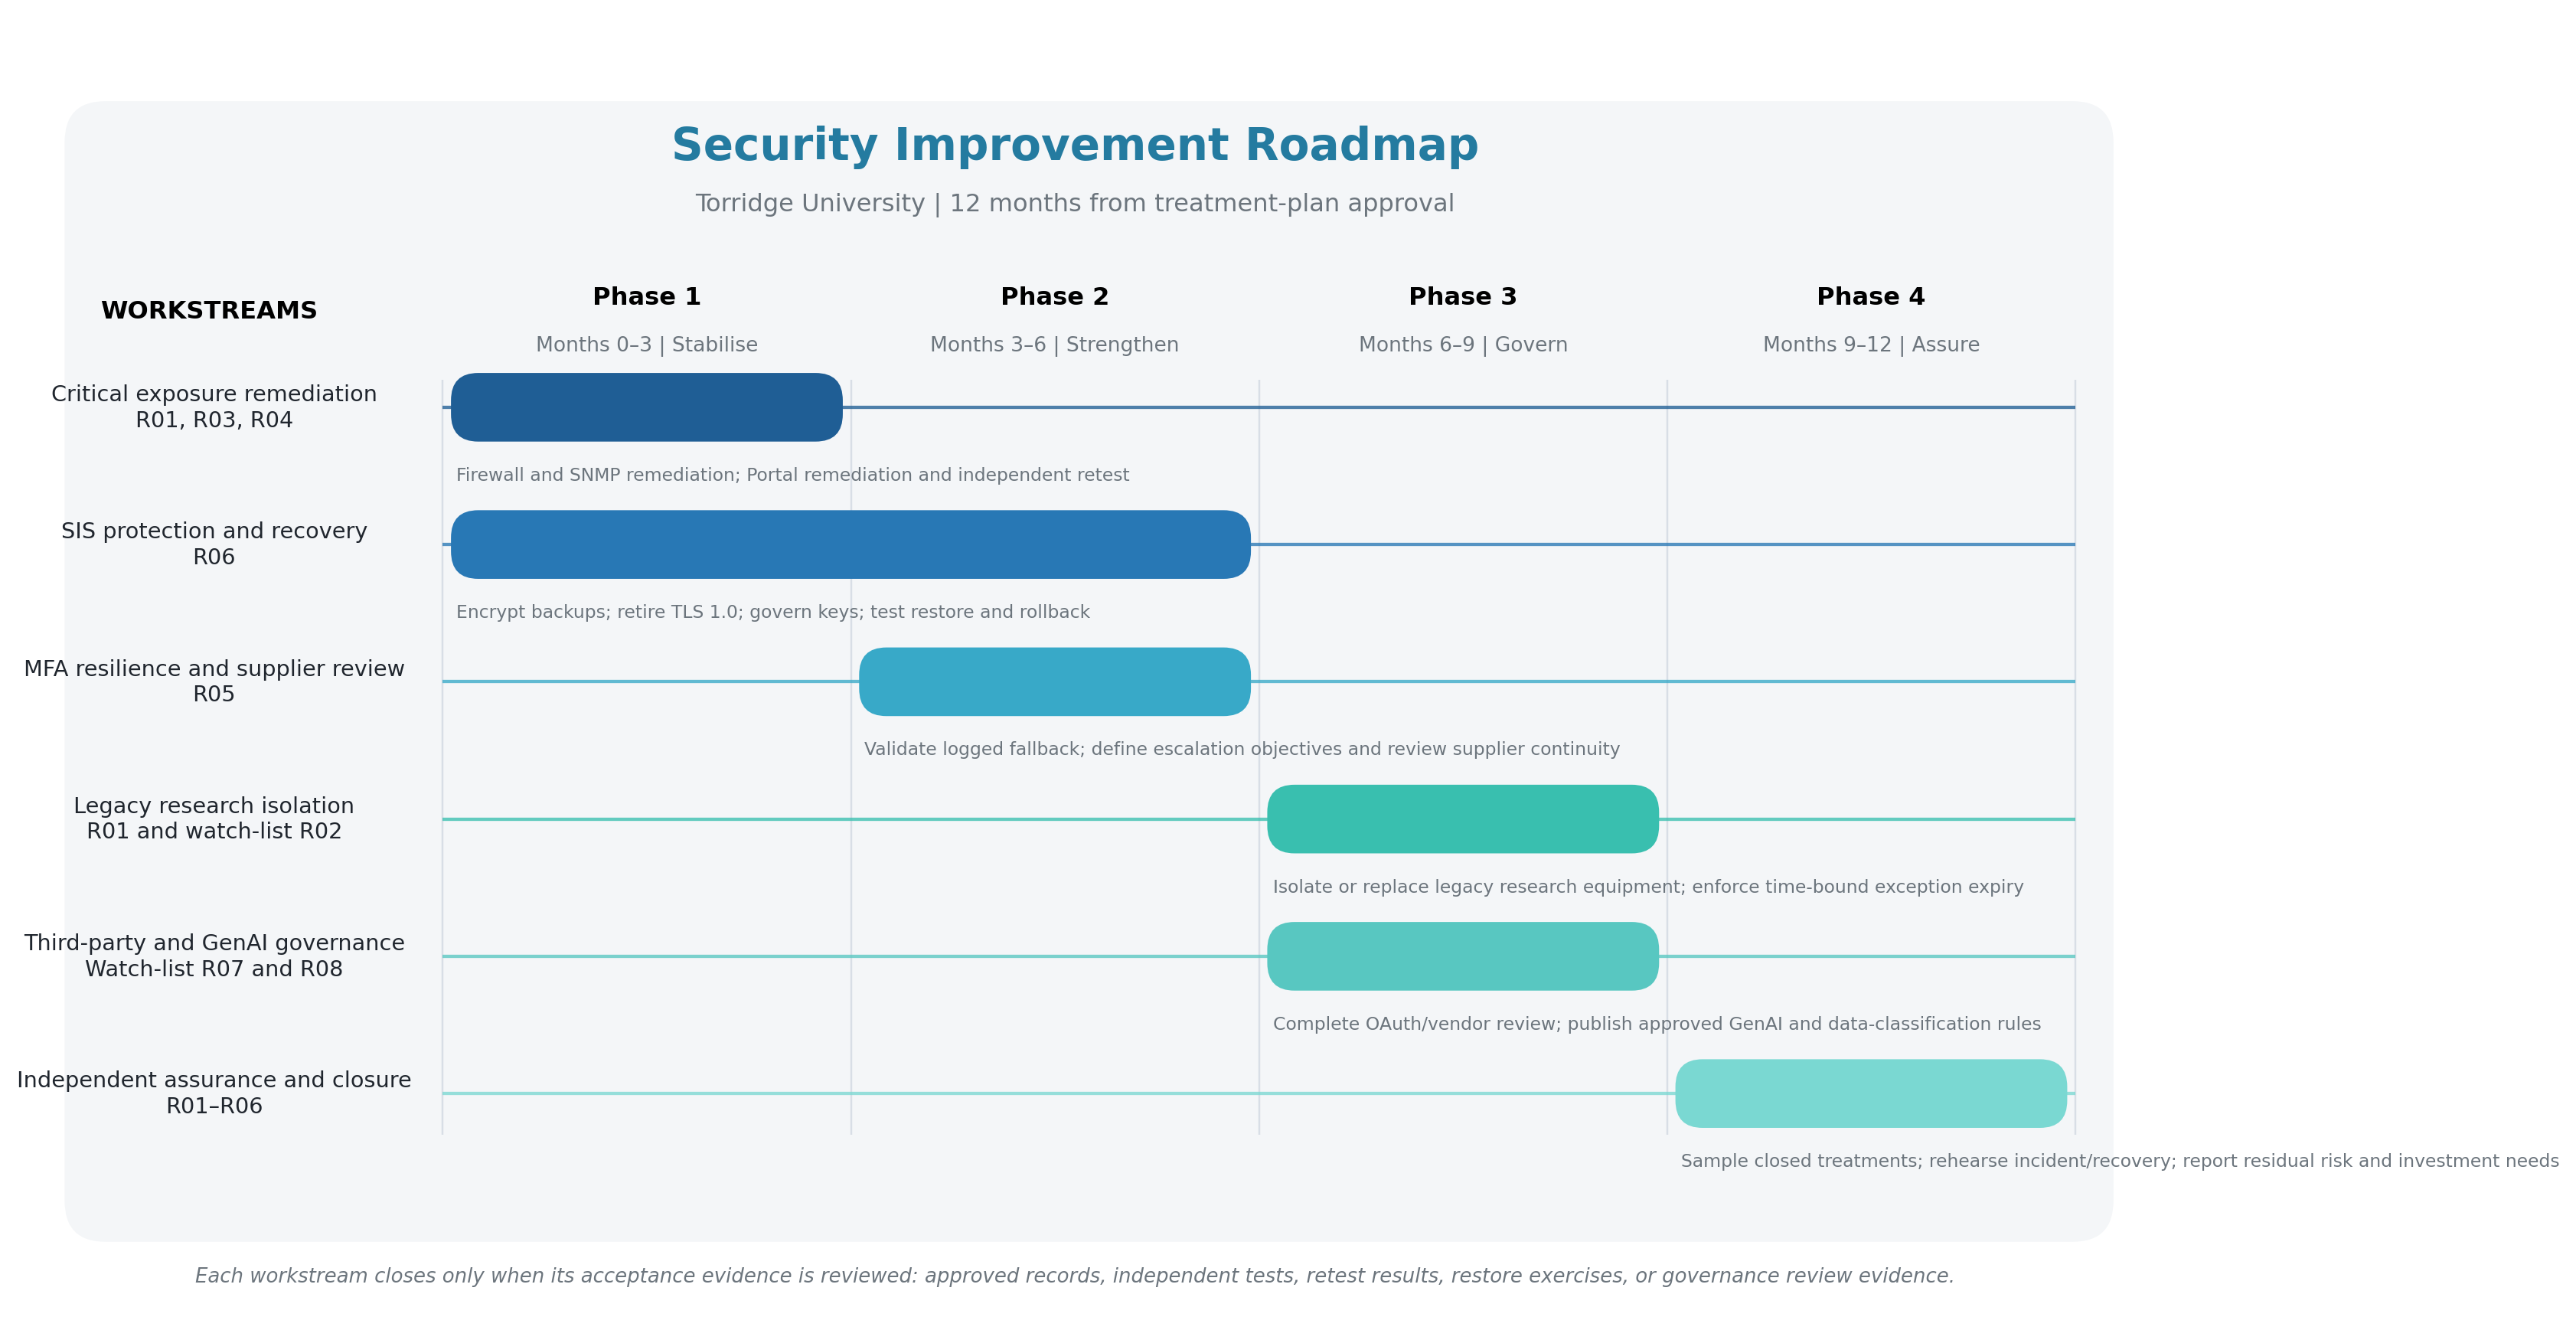

In [3]:
# Gantt-style roadmap: designed to match the supplied Cybersecurity Roadmap reference.
fig, ax = plt.subplots(figsize=(16, 10), dpi=220)
fig.patch.set_facecolor('white')
ax.set_facecolor('#F5F7FA')
ax.set_xlim(-2.9, 12.45)
ax.set_ylim(-1.25, 8.2)
ax.axis('off')

# Light rounded panel, aligned with the reference's restrained enterprise style.
panel = FancyBboxPatch((-2.7, -0.65), 14.9, 8.15,
                       boxstyle='round,pad=0.08,rounding_size=0.30',
                       linewidth=0, facecolor='#F4F6F8', zorder=0)
ax.add_patch(panel)

ax.text(4.65, 7.25, 'Security Improvement Roadmap', ha='center', va='center',
        fontsize=19, fontweight='bold', color=BLUE)
ax.text(4.65, 6.83, 'Torridge University | 12 months from treatment-plan approval',
        ha='center', va='center', fontsize=10.5, color=GREY)

# These four phases deliberately match the Part C roadmap table.
quarters = [(0, 3, 'Phase 1', 'Months 0–3 | Stabilise'),
            (3, 6, 'Phase 2', 'Months 3–6 | Strengthen'),
            (6, 9, 'Phase 3', 'Months 6–9 | Govern'),
            (9, 12, 'Phase 4', 'Months 9–12 | Assure')]
ax.text(-1.72, 6.05, 'WORKSTREAMS', ha='center', va='center', fontsize=10.5, fontweight='bold')
for start, end, phase, months in quarters:
    ax.text((start + end) / 2, 6.15, phase, ha='center', va='center', fontsize=10.5, fontweight='bold')
    ax.text((start + end) / 2, 5.80, months, ha='center', va='center', fontsize=8.7, color=GREY)
    ax.vlines(start, 0.05, 5.55, color='#D8DEE6', linewidth=0.8, zorder=1)
ax.vlines(12, 0.05, 5.55, color='#D8DEE6', linewidth=0.8, zorder=1)

# (label, start month, end month, colour, short delivery text)
workstreams = [
    ('Critical exposure remediation\nR01, R03, R04', 0.0, 3.0, '#1F5E95', 'Firewall and SNMP remediation; Portal remediation and independent retest'),
    ('SIS protection and recovery\nR06', 0.0, 6.0, '#2878B5', 'Encrypt backups; retire TLS 1.0; govern keys; test restore and rollback'),
    ('MFA resilience and supplier review\nR05', 3.0, 6.0, '#38A9C8', 'Validate logged fallback; define escalation objectives and review supplier continuity'),
    ('Legacy research isolation\nR01 and watch-list R02', 6.0, 9.0, '#39BFAF', 'Isolate or replace legacy research equipment; enforce time-bound exception expiry'),
    ('Third-party and GenAI governance\nWatch-list R07 and R08', 6.0, 9.0, '#58C7C1', 'Complete OAuth/vendor review; publish approved GenAI and data-classification rules'),
    ('Independent assurance and closure\nR01–R06', 9.0, 12.0, '#7AD8D2', 'Sample closed treatments; rehearse incident/recovery; report residual risk and investment needs'),
]

for y, (label, start, end, colour, delivery) in enumerate(workstreams[::-1]):
    ax.text(-1.68, y + 0.35, label, ha='center', va='center', fontsize=9.4, color='#20262E', linespacing=1.25)
    ax.hlines(y + 0.35, 0, 12, color=colour, linewidth=1.4, alpha=0.78, zorder=1)
    bar = FancyBboxPatch((start + 0.08, y + 0.12), max(end - start - 0.16, 0.22), 0.46,
                         boxstyle='round,pad=0.02,rounding_size=0.20',
                         linewidth=0, facecolor=colour, zorder=3)
    ax.add_patch(bar)
    # Delivery text remains underneath the bar for final report readability.
    ax.text(start + 0.10, y - 0.08, delivery, ha='left', va='top', fontsize=7.7, color=GREY)

ax.text(4.65, -0.98,
        'Each workstream closes only when its acceptance evidence is reviewed: approved records, independent tests, '
        'retest results, restore exercises, or governance review evidence.',
        ha='center', va='center', fontsize=8.5, color=GREY, style='italic')

fig.savefig(FIGURE_DIR / 'Figure_5_Strategic_Roadmap.png', dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(FIGURE_DIR / 'Figure_5_Strategic_Roadmap.svg', bbox_inches='tight', facecolor='white')
plt.show()


## Table 1 — Evidence Correlation Matrix

`P` denotes primary evidence for that risk and `S` denotes supporting evidence. A blank cell means that the item is not used to substantiate that primary risk. This is a traceability table, not proof that an incident occurred.

In [4]:
evidence_matrix = pd.DataFrame([
    ['E01', 'Technical assessment and configuration findings', 'S', 'P', 'S', '', ''],
    ['E02', 'SNMP service log: default strings accepted', '', '', 'P', '', ''],
    ['E03', 'Network overview and asset relationships', 'S', '', '', '', 'S'],
    ['E04', 'Firewall logs', 'P', '', '', '', ''],
    ['E05', 'Firewall configuration and access rules', 'P', '', '', '', ''],
    ['E06', 'IDS alerts', '', 'S', 'S', '', ''],
    ['E07', 'Student Portal web access logs', '', 'S', '', '', ''],
    ['E08', 'MFA incident evidence', '', '', '', 'P', ''],
    ['E09', 'Authentication evidence', '', '', '', 'P', ''],
    ['E10', 'MFA and identity-service continuity evidence', '', '', '', 'S', ''],
    ['E11', 'SIS cryptography, backup and key-management evidence', '', '', '', '', 'P'],
    ['E12', 'SIS change and recovery-control record', '', '', '', '', 'P'],
    ['E13', 'Legacy research exception record', 'S', '', '', '', ''],
    ['E15', 'Staff feedback relevant to identity continuity', '', '', '', 'S', ''],
], columns=[
    'Evidence ID', 'Evidence source',
    'R01\nSegmentation', 'R03\nPortal', 'R04\nSNMP',
    'R05\nMFA', 'R06\nSIS / recovery'
])

# Export a reusable source table.
evidence_matrix.to_csv(TABLE_DIR / 'Table_1_Evidence_Correlation_Matrix.csv', index=False, encoding='utf-8-sig')

display(evidence_matrix)


,Evidence ID,Evidence source,R01\nSegmentation,R03\nPortal,R04\nSNMP,R05\nMFA,R06\nSIS / recovery
0,E01,Technical assessment and configuration findings,S,P,S,,
1,E02,SNMP service log: default strings accepted,,,P,,
2,E03,Network overview and asset relationships,S,,,,S
3,E04,Firewall logs,P,,,,
4,E05,Firewall configuration and access rules,P,,,,
5,E06,IDS alerts,,S,S,,
6,E07,Student Portal web access logs,,S,,,
7,E08,MFA incident evidence,,,,P,
8,E09,Authentication evidence,,,,P,
9,E10,MFA and identity-service continuity evidence,,,,S,


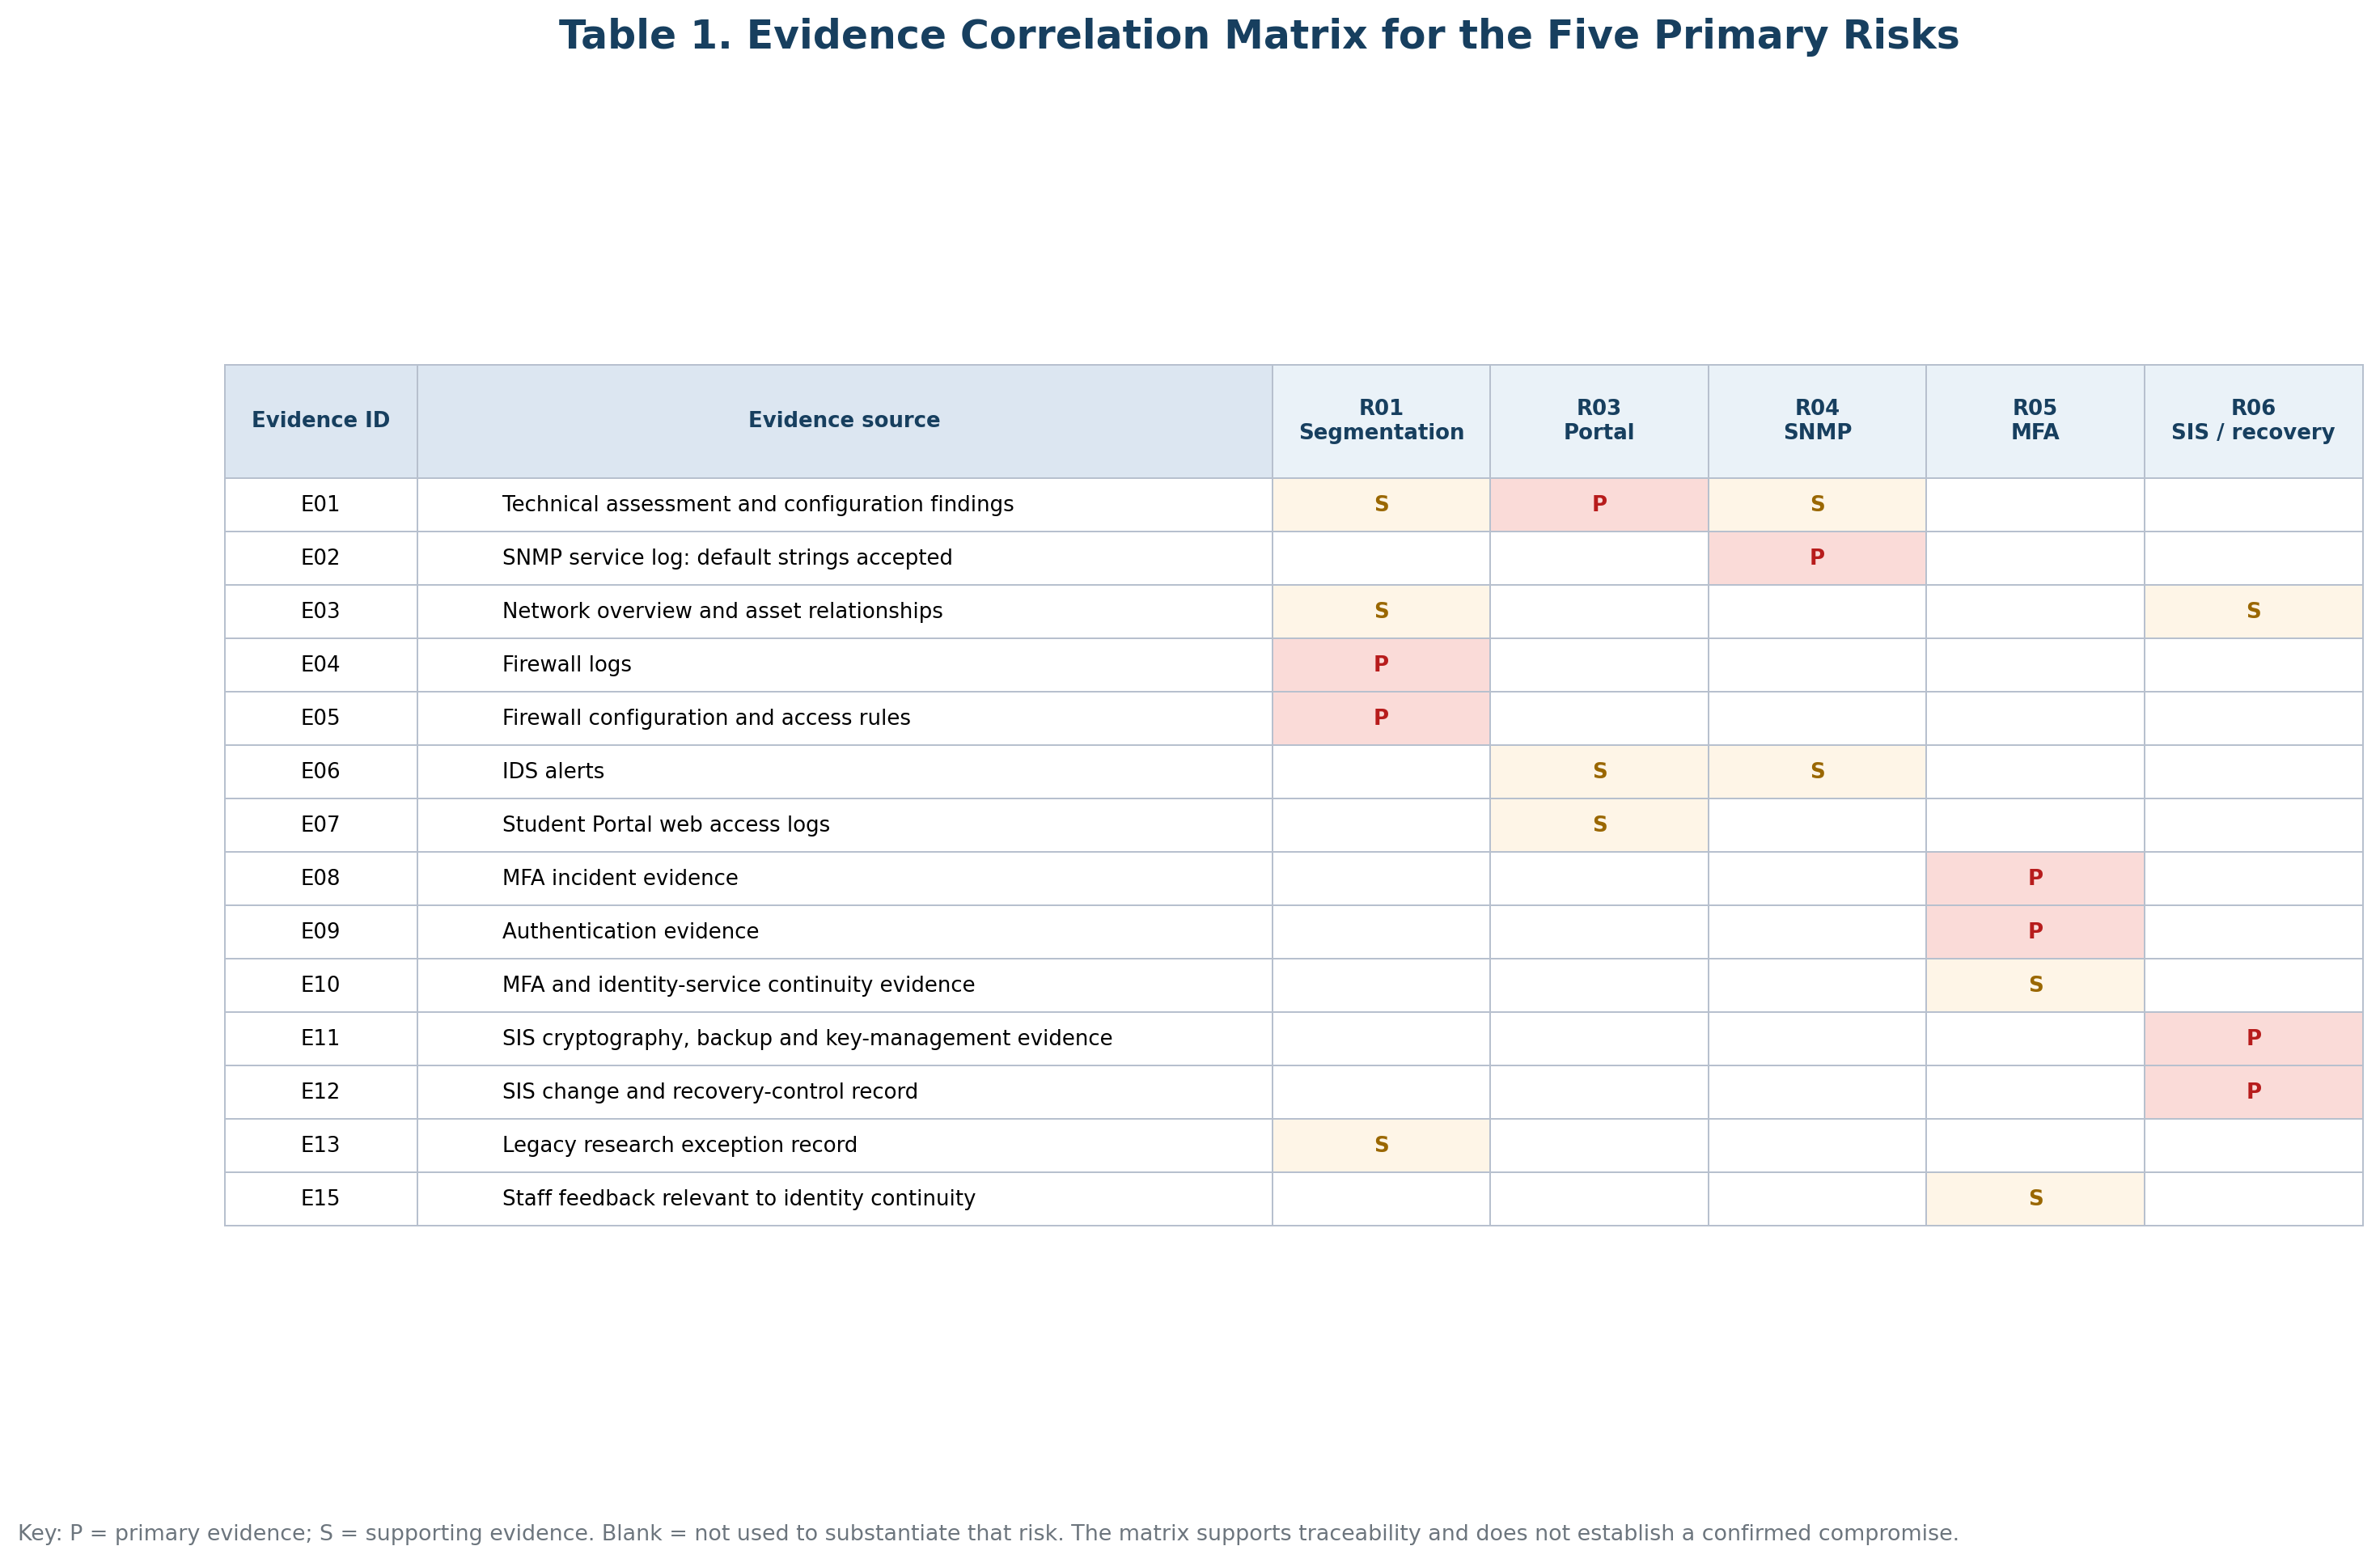

Generated:
 - /content/figures/Figure_4_Security_Control_Strategy.png
 - /content/figures/Figure_5_Strategic_Roadmap.png
 - /content/tables/Table_1_Evidence_Correlation_Matrix.png
 - /content/tables/Table_1_Evidence_Correlation_Matrix.csv


In [5]:
# Render the same matrix as a high-resolution academic-report table.
fig, ax = plt.subplots(figsize=(15.5, 9.2), dpi=220)
ax.axis('off')
fig.suptitle('Table 1. Evidence Correlation Matrix for the Five Primary Risks',
             fontsize=16, fontweight='bold', color=NAVY, y=0.97)

table = ax.table(
    cellText=evidence_matrix.values,
    colLabels=evidence_matrix.columns,
    colColours=['#DCE6F1', '#DCE6F1', '#EAF2F8', '#EAF2F8', '#EAF2F8', '#EAF2F8', '#EAF2F8'],
    cellLoc='center',
    colLoc='center',
    loc='center',
    colWidths=[0.09, 0.40, 0.102, 0.102, 0.102, 0.102, 0.102],
)

table.auto_set_font_size(False)
table.set_fontsize(8.5)
table.scale(1, 1.8)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#B7C0CE')
    cell.set_linewidth(0.65)
    if row == 0:
        cell.set_text_props(fontweight='bold', color=NAVY)
        cell.set_height(0.09)
    elif col == 1:
        cell.set_text_props(ha='left')
    if row > 0 and col >= 2:
        value = evidence_matrix.iloc[row - 1, col]
        if value == 'P':
            cell.set_facecolor('#FADBD8')
            cell.set_text_props(fontweight='bold', color=RED)
        elif value == 'S':
            cell.set_facecolor('#FEF5E7')
            cell.set_text_props(fontweight='bold', color='#9A6700')
        else:
            cell.set_facecolor('#FFFFFF')

fig.text(0.05, 0.04,
         'Key: P = primary evidence; S = supporting evidence. Blank = not used to substantiate that risk. '
         'The matrix supports traceability and does not establish a confirmed compromise.',
         fontsize=8.8, color=GREY)

fig.savefig(TABLE_DIR / 'Table_1_Evidence_Correlation_Matrix.png', dpi=300, bbox_inches='tight')
fig.savefig(TABLE_DIR / 'Table_1_Evidence_Correlation_Matrix.svg', bbox_inches='tight')
plt.show()

print('Generated:')
for path in [
    FIGURE_DIR / 'Figure_4_Security_Control_Strategy.png',
    FIGURE_DIR / 'Figure_5_Strategic_Roadmap.png',
    TABLE_DIR / 'Table_1_Evidence_Correlation_Matrix.png',
    TABLE_DIR / 'Table_1_Evidence_Correlation_Matrix.csv',
]:
    print(' -', path.resolve())
